# Data Discovery

What the data is, before deciding what to predict: each source's size, grain, IDs, and coverage over time, how the sources join, candidate targets, and a drafted data dictionary. Every check below is short pandas code, so you can read it, change it, and rerun it.

**How to use this notebook.** The cells marked *Decision* hold the choices: which files, the main source, and the answers for the data dictionary. Edit them, then choose Run All. The last cells write `docs/data_dictionary.yaml` and the `discovery` section of `ml_spec.yaml`.

**Privacy.** Raw rows appear only once, in the *First Rows* cell. Everything else is counts and summaries.

## Setup

Finds the project root, loads the shared spec `ml_spec.yaml`, and checks the kernel. Run this cell first.

In [1]:
import os
import sys
from pathlib import Path

# The project root is the closest folder with ml_spec.yaml. Everything runs from there.
here = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in here if (p / "ml_spec.yaml").is_file()), Path.cwd())
os.chdir(ROOT)
# The project's own code (src) comes from this folder, also in an experiment's worktree, where the editable
# install in .venv would point to the main project.
sys.path.insert(0, str(ROOT))

# Shared code from the ML project skills
sys.path.insert(0, r"/Users/ani/.claude/skills/ml-data-discovery/scripts")
import ml_common
import nb_common
try:  # MLflow tracking, in the ML project skills: keeps a copy of each chart for the stage's run
    import tracking
    tracking.capture_figures()
except ImportError:
    tracking = None

SPEC_PATH = str(ROOT / "ml_spec.yaml")
spec = ml_common.migrate(ml_common.load(SPEC_PATH)) if os.path.exists(SPEC_PATH) else ml_common.template()
PATHS = ml_common.project_paths(spec, str(ROOT))
NOTEBOOK = os.path.join(PATHS["notebooks"], "02_data_discovery.ipynb")
STAGE = "discovery"

print("Project root:", ROOT)
print("Python:", sys.executable)
if (ROOT / ".venv").is_dir() and Path(sys.prefix).resolve() != (ROOT / ".venv").resolve():
    print("Warning: this kernel is not the project's .venv. Choose 'Select Kernel' and pick the project kernel.")

Project root: /Users/ani/Projects/16_weather_prediction
Python: /Users/ani/Projects/16_weather_prediction/.venv/bin/python


In [2]:
import re

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

import discover
from eda_core import load_data, suggest_targets

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

## Sources

The data files to profile, as `name: path` from the project root, and the main source: the one the model will most likely be trained on.

In [3]:
# Decision
SOURCES = {'weather': 'data/raw/open_meteo_daily_2024-01-01_2026-10-01.csv'}

MAIN = 'weather'

# Optional: the main date column of a source, when the automatic choice below is wrong, as name: column
DATE_COLUMNS = {}

# Optional: one sentence on what each source is and where it comes from
SOURCE_DESCRIPTIONS = {
    'weather': 'Daily weather for 50 cities from the Open-Meteo Historical Weather API (archive), 2024-01-01 to 2026-10-01, one row per city and local date. Modelled data (ECMWF IFS and ERA5 reanalysis), not station observations. Downloaded by src/download_weather.py; the request URLs are in the .meta.json beside the file.',
}

In [4]:
frames = {name: load_data(path) for name, path in SOURCES.items()}
for name, df in frames.items():
    print(f"{name}: {len(df):,} rows and {df.shape[1]} columns from {SOURCES[name]}")

weather: 50,250 rows and 23 columns from data/raw/open_meteo_daily_2024-01-01_2026-10-01.csv


## First Rows

The only cell that shows raw rows.

In [5]:
for name, df in frames.items():
    print(name)
    display(df.head())

weather


,city,country,latitude,longitude,grid_latitude,grid_longitude,elevation,timezone,date,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_max,apparent_temperature_min,precipitation_sum,rain_sum,snowfall_sum,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,sunshine_duration,weather_code
0,London,United Kingdom,51.5074,-0.1278,51.493847,-0.163025,16.0,Europe/London,2024-01-01,10.9,5.8,7.7,6.3,1.0,10.5,10.5,0.0,30.6,51.8,225,2.39,6276.83,61
1,London,United Kingdom,51.5074,-0.1278,51.493847,-0.163025,16.0,Europe/London,2024-01-02,12.9,8.4,11.1,8.9,2.5,7.4,7.4,0.0,52.3,90.4,230,0.56,0.00,61
2,London,United Kingdom,51.5074,-0.1278,51.493847,-0.163025,16.0,Europe/London,2024-01-03,10.4,6.3,8.4,6.2,2.7,2.3,2.3,0.0,25.9,45.7,245,2.71,27210.10,61
3,London,United Kingdom,51.5074,-0.1278,51.493847,-0.163025,16.0,Europe/London,2024-01-04,8.3,4.8,6.8,6.0,1.5,30.3,30.3,0.0,27.4,46.8,240,2.30,10052.49,65
4,London,United Kingdom,51.5074,-0.1278,51.493847,-0.163025,16.0,Europe/London,2024-01-05,7.1,4.4,5.7,3.3,-1.0,2.1,2.1,0.0,33.7,57.2,309,2.04,3184.94,63


## Columns and Types

The type, missing share, and number of distinct values of every column.

In [6]:
for name, df in frames.items():
    overview = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing %": (df.isna().mean() * 100).round(1),
        "unique": df.nunique(),
    })
    print(f"{name}: {df.shape[1]} columns")
    display(overview)

weather: 23 columns


,dtype,missing %,unique
city,str,0.0,50
country,str,0.0,36
latitude,float64,0.0,50
longitude,float64,0.0,50
grid_latitude,float64,0.0,48
grid_longitude,float64,0.0,50
elevation,float64,0.0,42
timezone,str,0.0,43
date,str,0.0,1005
temperature_2m_max,float64,0.0,638


## Grain

What makes a row unique. First single columns, then pairs of columns. Decimal measures are skipped, because they pair up with almost anything into a unique combination. A grain of *unclear* means one row's meaning has to be confirmed with the data owner.

In [7]:
def unique_keys(df, max_cols=10):
    """The first column, or else pair of columns, that is unique for every row (after removing exact duplicates)."""
    data = df.drop_duplicates()
    n = len(data)
    singles = [c for c in data.columns if data[c].notna().all() and data[c].nunique() == n]
    if singles:
        return singles[:1]
    cands = [c for c in data.columns if 1 < data[c].nunique() < n and not pd.api.types.is_float_dtype(data[c])]
    cands = sorted(cands, key=lambda c: -data[c].nunique())[:max_cols]
    for i, a in enumerate(cands):
        for b in cands[i + 1:]:
            if data[[a, b]].notna().all().all() and not data.duplicated(subset=[a, b]).any():
                return [a, b]
    return []


for name, df in frames.items():
    key = unique_keys(df)
    grain = " + ".join(key) if key else "unclear"
    print(f"{name}: {df.duplicated().sum():,} exact duplicate rows. One row per: {grain}")

weather: 0 exact duplicate rows. One row per: date + city


## Possible Entity IDs

Columns named like IDs, with how many rows each value has. An ID with several rows per value (a customer with many orders) means the split later must keep each entity on one side, or split by time.

In [8]:
ID_LIKE = re.compile(r"(^id$|_id$|^id_|uuid|guid|_key$|^key$|_no$|number$)", re.I)

for name, df in frames.items():
    rows = [{"column": c, "distinct values": df[c].nunique(), "rows per value": round(len(df) / max(df[c].nunique(), 1), 2)}
            for c in df.columns if ID_LIKE.search(str(c))]
    print(name)
    display(pd.DataFrame(rows) if rows else "No ID-like columns.")

weather


'No ID-like columns.'

## Coverage Over Time

The main date column of each source, its range, how recent the latest row is, and rows per month. A month with no rows is either a real gap or a missing load. Set `DATE_COLUMNS` above when the automatic choice is wrong.

weather: date runs from 2024-01-01 to 2026-10-01 (1,004 days). The latest row is 19 days old. Months with no rows: none.


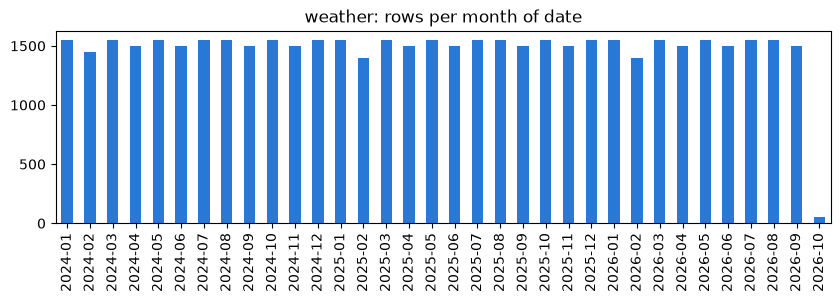

In [9]:
def main_date(df, name):
    """DATE_COLUMNS when set, else the first column stored as dates, else the first text column that reads as dates."""
    if name in DATE_COLUMNS:
        return DATE_COLUMNS[name]
    for c in df.columns:
        if pd.api.types.is_datetime64_any_dtype(df[c]):
            return c
    for c in df.columns:
        if pd.api.types.is_object_dtype(df[c]) or pd.api.types.is_string_dtype(df[c]):
            sample = df[c].dropna().astype(str).head(500)
            looks_numeric = pd.to_numeric(sample, errors="coerce").notna().mean() > 0.5
            if len(sample) and not looks_numeric and pd.to_datetime(sample, errors="coerce", format="mixed").notna().mean() > 0.9:
                return c
    return None


dates = {name: main_date(df, name) for name, df in frames.items()}
for name, df in frames.items():
    col = dates[name]
    if col is None:
        print(f"{name}: no date column found.")
        continue
    d = pd.to_datetime(df[col], errors="coerce", format="mixed")
    per_month = d.dt.to_period("M").value_counts().sort_index()
    per_month = per_month.reindex(pd.period_range(per_month.index.min(), per_month.index.max(), freq="M"), fill_value=0)
    gaps = [str(p) for p, v in per_month.items() if v == 0]
    age = (pd.Timestamp.today().normalize() - d.max().normalize()).days
    print(f"{name}: {col} runs from {d.min():%Y-%m-%d} to {d.max():%Y-%m-%d} ({(d.max() - d.min()).days:,} days). "
          f"The latest row is {age:,} days old. Months with no rows: {', '.join(gaps) or 'none'}.")
    ax = per_month.plot(kind="bar", figsize=(10, 2.5), color="#2a78d6", title=f"{name}: rows per month of {col}")
    ax.set_xlabel("")
    plt.show()

## Missing Values

The columns with the most missing values in each source.

In [10]:
for name, df in frames.items():
    missing = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
    missing = missing[missing > 0]
    print(f"{name}: {len(missing)} of {df.shape[1]} columns have missing values")
    if len(missing):
        display(missing.head(15).to_frame("missing %"))

weather: 0 of 23 columns have missing values


## How the Sources Join

For every column two sources share, the share of rows on each side that find a match, and the most rows one key value has on each side. More than one row per key on both sides means a join multiplies rows, so one side has to be aggregated first.

In [11]:
names = list(frames)
if len(names) < 2:
    print("There is one source, so there are no joins to check.")
for i, a in enumerate(names):
    for b in names[i + 1:]:
        shared = [c for c in frames[a].columns
                  if c in frames[b].columns and not pd.api.types.is_float_dtype(frames[a][c])]
        if not shared:
            print(f"{a} and {b} share no column that could be a join key.")
        for key in shared:
            left, right = frames[a][key], frames[b][key]
            print(f"{a} and {b} on {key}: {left.isin(right).mean():.1%} of {a} rows and {right.isin(left).mean():.1%} "
                  f"of {b} rows find a match. Most rows per key: {left.value_counts().max():,} in {a}, "
                  f"{right.value_counts().max():,} in {b}.")

There is one source, so there are no joins to check.


## Candidate Targets

Columns in the main source that look like an outcome, ranked by their name and their values, with the class balance of the yes or no ones. The target itself is chosen in `03_problem_framing.ipynb`.

In [12]:
candidates = pd.DataFrame([c for c in suggest_targets(frames[MAIN], top=5) if c["score"] > 0])
if candidates.empty:
    print("No column looks like a target. It will probably be built from events in a time window.")
else:
    display(candidates[["column", "suggested_type", "unique", "missing_pct", "reasons"]])
    for c in candidates.itertuples():
        if c.unique == 2:
            print(f"{c.column}: class shares {frames[MAIN][c.column].value_counts(normalize=True).round(3).to_dict()}")

,column,suggested_type,unique,missing_pct,reasons
0,wind_speed_10m_max,continuous,511,0.0,"[name suggests an outcome, continuous numeric]"
1,wind_gusts_10m_max,continuous,295,0.0,"[name suggests an outcome, continuous numeric]"
2,wind_direction_10m_dominant,continuous,361,0.0,"[name suggests an outcome, continuous numeric]"
3,city,categorical,50,0.0,[first column]
4,weather_code,categorical,13,0.0,[last column]


## Columns That May Be Recorded After the Outcome

Columns whose names suggest something that happens later, such as a refund, a chargeback, a cancellation, or a final status. Each one needs a decision before it can be a feature, because it may leak the outcome.

In [13]:
AFTER_OUTCOME = discover.POST_HINT  # refund, chargeback, cancel, closed, resolved, settled, final, outcome, ...
for name, df in frames.items():
    found = [c for c in df.columns if AFTER_OUTCOME.search(str(c))]
    print(f"{name}: {', '.join(found) or 'none'}")

weather: none


## Data Dictionary (Draft)

Every column with a meaning drafted from its name and the data, and its timing: when it is filled in relative to the prediction. Columns whose meaning or timing could not be worked out are left blank and flagged for review. The rules are in `reference/dictionary_rules.md` of the ml-data-discovery skill. This cell also profiles each source with the shared EDA engine, which takes a little longer on large files.

In [14]:
disc = discover.Discovery(SPEC_PATH, frames, SOURCES, MAIN, date_columns=dates)
for name, cov in disc.coverage.items():
    if cov and cov["column"] != dates[name]:
        print(f"Note: the EDA engine chose {cov['column']} as the main date of {name}. Set DATE_COLUMNS to override.")
display(disc.table())

,source,column,role,meaning,timing,flags,review
0,weather,city,identifier,"City name, chosen in the downloader's city list. Together with date it ident...",static,,
1,weather,country,categorical,Country of the city.,static,,
2,weather,latitude,numeric,"Latitude of the city as requested, in decimal degrees (WGS84).",static,timing unknown,
3,weather,longitude,numeric,"Longitude of the city as requested, in decimal degrees (WGS84).",static,timing unknown,
4,weather,grid_latitude,numeric,"Latitude of the centre of the model grid cell the API used, which can be a f...",static,timing unknown,
5,weather,grid_longitude,numeric,Longitude of the centre of the model grid cell the API used.,static,timing unknown,
6,weather,elevation,numeric,"Elevation of the location used by the API, in metres above sea level.",static,timing unknown,
7,weather,timezone,categorical,IANA timezone the API assigned from the coordinates (timezone=auto). Daily v...,static,timing unknown,
8,weather,date,date stored as text,Local calendar date of the row (in the city's timezone).,event_time,,
9,weather,temperature_2m_max,numeric,Maximum air temperature at 2 m above ground during the day. Unit: degrees Ce...,at_event,,


### Columns to Review

In [15]:
review = disc.table(needs_review_only=True)
print(f"{len(review)} columns need review.")
display(review)

0 columns need review.


""


## Answers for the Dictionary

Fill in what each flagged column means and when it is filled in, as `"source.column": {...}`. Allowed timings: `identifier`, `static`, `event_time`, `before_prediction`, `at_event`, `possibly_after_outcome`, `unknown`. Answers marked `"source": "user"` (the default) count as confirmed. Answers are kept when the notebook runs again.

In [16]:
# Decision
dictionary_answers = {
    'weather.city': {
        'meaning': "City name, chosen in the downloader's city list. Together with date it identifies a row.",
        'timing': 'static',
        'source': 'reviewed',
        'notes': 'Fixed per city. Source: Open-Meteo Historical Weather API docs and src/download_weather.py.',
    },
    'weather.country': {
        'meaning': 'Country of the city.',
        'timing': 'static',
        'source': 'reviewed',
        'notes': 'Fixed per city. Source: Open-Meteo Historical Weather API docs and src/download_weather.py.',
    },
    'weather.latitude': {
        'meaning': 'Latitude of the city as requested, in decimal degrees (WGS84).',
        'timing': 'static',
        'source': 'reviewed',
        'notes': 'Fixed per city. Source: Open-Meteo Historical Weather API docs and src/download_weather.py.',
    },
    'weather.longitude': {
        'meaning': 'Longitude of the city as requested, in decimal degrees (WGS84).',
        'timing': 'static',
        'source': 'reviewed',
        'notes': 'Fixed per city. Source: Open-Meteo Historical Weather API docs and src/download_weather.py.',
    },
    'weather.grid_latitude': {
        'meaning': 'Latitude of the centre of the model grid cell the API used, which can be a few km from the requested point.',
        'timing': 'static',
        'source': 'reviewed',
        'notes': 'Fixed per city. Source: Open-Meteo Historical Weather API docs and src/download_weather.py.',
    },
    'weather.grid_longitude': {
        'meaning': 'Longitude of the centre of the model grid cell the API used.',
        'timing': 'static',
        'source': 'reviewed',
        'notes': 'Fixed per city. Source: Open-Meteo Historical Weather API docs and src/download_weather.py.',
    },
    'weather.elevation': {
        'meaning': 'Elevation of the location used by the API, in metres above sea level.',
        'timing': 'static',
        'source': 'reviewed',
        'notes': 'Fixed per city. Source: Open-Meteo Historical Weather API docs and src/download_weather.py.',
    },
    'weather.timezone': {
        'meaning': 'IANA timezone the API assigned from the coordinates (timezone=auto). Daily values follow this local calendar day.',
        'timing': 'static',
        'source': 'reviewed',
        'notes': 'Fixed per city. Source: Open-Meteo Historical Weather API docs and src/download_weather.py.',
    },
    'weather.date': {
        'meaning': "Local calendar date of the row (in the city's timezone).",
        'timing': 'event_time',
        'source': 'reviewed',
        'notes': 'One row per city per date. Source: Open-Meteo Historical Weather API docs and src/download_weather.py.',
    },
    'weather.temperature_2m_max': {
        'meaning': 'Maximum air temperature at 2 m above ground during the day. Unit: degrees Celsius.',
        'timing': 'at_event',
        'source': 'reviewed',
        'notes': "Describes the row's local calendar date (timezone=auto) and is known at the end of that day. A next day target is built by shifting the date, so the value itself is not after the outcome. Source: Open-Meteo Historical Weather API docs and src/download_weather.py.",
    },
    'weather.temperature_2m_min': {
        'meaning': 'Minimum air temperature at 2 m above ground during the day. Unit: degrees Celsius.',
        'timing': 'at_event',
        'source': 'reviewed',
        'notes': "Describes the row's local calendar date (timezone=auto) and is known at the end of that day. A next day target is built by shifting the date, so the value itself is not after the outcome. Source: Open-Meteo Historical Weather API docs and src/download_weather.py.",
    },
    'weather.temperature_2m_mean': {
        'meaning': 'Mean air temperature at 2 m above ground during the day. Unit: degrees Celsius.',
        'timing': 'at_event',
        'source': 'reviewed',
        'notes': "Describes the row's local calendar date (timezone=auto) and is known at the end of that day. A next day target is built by shifting the date, so the value itself is not after the outcome. Source: Open-Meteo Historical Weather API docs and src/download_weather.py.",
    },
    'weather.apparent_temperature_max': {
        'meaning': 'Maximum apparent (feels like) temperature during the day, combining temperature, wind, humidity and radiation. Unit: degrees Celsius.',
        'timing': 'at_event',
        'source': 'reviewed',
        'notes': "Describes the row's local calendar date (timezone=auto) and is known at the end of that day. A next day target is built by shifting the date, so the value itself is not after the outcome. Source: Open-Meteo Historical Weather API docs and src/download_weather.py.",
    },
    'weather.apparent_temperature_min': {
        'meaning': 'Minimum apparent (feels like) temperature during the day. Unit: degrees Celsius.',
        'timing': 'at_event',
        'source': 'reviewed',
        'notes': "Describes the row's local calendar date (timezone=auto) and is known at the end of that day. A next day target is built by shifting the date, so the value itself is not after the outcome. Source: Open-Meteo Historical Weather API docs and src/download_weather.py.",
    },
    'weather.precipitation_sum': {
        'meaning': 'Total precipitation during the day (rain, showers, and snowfall as water). Unit: mm.',
        'timing': 'at_event',
        'source': 'reviewed',
        'notes': "Describes the row's local calendar date (timezone=auto) and is known at the end of that day. A next day target is built by shifting the date, so the value itself is not after the outcome. Source: Open-Meteo Historical Weather API docs and src/download_weather.py.",
    },
    'weather.rain_sum': {
        'meaning': 'Total rain during the day. Unit: mm.',
        'timing': 'at_event',
        'source': 'reviewed',
        'notes': "Describes the row's local calendar date (timezone=auto) and is known at the end of that day. A next day target is built by shifting the date, so the value itself is not after the outcome. Source: Open-Meteo Historical Weather API docs and src/download_weather.py.",
    },
    'weather.snowfall_sum': {
        'meaning': 'Total snowfall during the day. Unit: cm.',
        'timing': 'at_event',
        'source': 'reviewed',
        'notes': "Describes the row's local calendar date (timezone=auto) and is known at the end of that day. A next day target is built by shifting the date, so the value itself is not after the outcome. Source: Open-Meteo Historical Weather API docs and src/download_weather.py.",
    },
    'weather.wind_speed_10m_max': {
        'meaning': 'Maximum wind speed at 10 m above ground during the day. Unit: km/h.',
        'timing': 'at_event',
        'source': 'reviewed',
        'notes': "Describes the row's local calendar date (timezone=auto) and is known at the end of that day. A next day target is built by shifting the date, so the value itself is not after the outcome. Source: Open-Meteo Historical Weather API docs and src/download_weather.py.",
    },
    'weather.wind_gusts_10m_max': {
        'meaning': 'Maximum wind gust at 10 m above ground during the day. Unit: km/h.',
        'timing': 'at_event',
        'source': 'reviewed',
        'notes': "Describes the row's local calendar date (timezone=auto) and is known at the end of that day. A next day target is built by shifting the date, so the value itself is not after the outcome. Source: Open-Meteo Historical Weather API docs and src/download_weather.py.",
    },
    'weather.wind_direction_10m_dominant': {
        'meaning': 'Dominant wind direction at 10 m above ground during the day. Unit: degrees (0 to 360, from north).',
        'timing': 'at_event',
        'source': 'reviewed',
        'notes': "Describes the row's local calendar date (timezone=auto) and is known at the end of that day. A next day target is built by shifting the date, so the value itself is not after the outcome. Source: Open-Meteo Historical Weather API docs and src/download_weather.py.",
    },
    'weather.shortwave_radiation_sum': {
        'meaning': 'Total shortwave solar radiation during the day. Unit: MJ per square metre.',
        'timing': 'at_event',
        'source': 'reviewed',
        'notes': "Describes the row's local calendar date (timezone=auto) and is known at the end of that day. A next day target is built by shifting the date, so the value itself is not after the outcome. Source: Open-Meteo Historical Weather API docs and src/download_weather.py.",
    },
    'weather.sunshine_duration': {
        'meaning': 'Duration of sunshine during the day. Unit: seconds.',
        'timing': 'at_event',
        'source': 'reviewed',
        'notes': "Describes the row's local calendar date (timezone=auto) and is known at the end of that day. A next day target is built by shifting the date, so the value itself is not after the outcome. Source: Open-Meteo Historical Weather API docs and src/download_weather.py.",
    },
    'weather.weather_code': {
        'meaning': 'Most severe weather condition of the day, as a WMO weather code (for example 0 clear, 61 rain, 71 snow).',
        'timing': 'at_event',
        'source': 'reviewed',
        'notes': "Describes the row's local calendar date (timezone=auto) and is known at the end of that day. A next day target is built by shifting the date, so the value itself is not after the outcome. Source: Open-Meteo Historical Weather API docs and src/download_weather.py.",
    },
}

## Write to the Spec

Applies the answers, writes `docs/data_dictionary.yaml` and the `discovery` section of `ml_spec.yaml`, and records this run.

In [17]:
unknown = disc.apply(dictionary_answers)
if unknown:
    print("These answers match no column: " + ", ".join(unknown))
summary = disc.write(SOURCE_DESCRIPTIONS)
nb_common.record_run(SPEC_PATH, STAGE, NOTEBOOK, "ml-data-discovery")
ds = summary["dictionary_summary"]
print(f"Wrote {summary['dictionary']} and the discovery section of ml_spec.yaml.")
print(f"Dictionary: {ds['columns']} columns, {ds['needs_review']} still need review.")
display(disc.table(needs_review_only=True))

Wrote docs/data_dictionary.yaml and the discovery section of ml_spec.yaml.
Dictionary: 23 columns, 0 still need review.


""


## Next Step

Answer the flagged columns above, especially the ones that may be recorded after the outcome, and rerun this notebook. Then run `/ml-problem-framing`, which proposes the target, unit of prediction, and prediction time from these findings. Check progress with `/ml-status`.